# Determining the effect of the WR selection criteria on results

In [1]:
from posydon.utils.common_functions import convert_metallicity_to_string, orbital_separation_from_period
from posydon.popsyn.distributions import PowerLawPeriod
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cmap import Colormap
import pickle
from pathlib import Path
from tqdm import tqdm
from scipy.stats import gaussian_kde
from helper_functions import calc_Teff, optical_depth_calculation

tol_vibrant = Colormap('tol:vibrant')(np.linspace(0, 1, 7))

COLORS = {0.0001: '#1f4e79',
           0.001: '#2e75b6',
            0.01: '#5ba3d0', 
             0.1: '#f4a261',
             0.2: '#e76f51',
            0.45: '#c0392b', 
             1.0: '#8e1a0e',
             2.0: '#5c0a0a'
             }

In [ ]:
def load_metallicity(metallicity, data_folder):
    """Load and process WR phase data for a single metallicity.

    Returns a dict of arrays ready for analysis.
    """
    met_str = convert_metallicity_to_string(metallicity)
    file_path = data_folder / f'WR_phases_Z{met_str}_Zsun.pkl'
    with open(file_path, 'rb') as f:
        data = pickle.load(f)

    S1_WR_data = data['S1_WR_data']
    S2_WR_data = data['S2_WR_data']

    s1 = pd.concat(S1_WR_data.values(), keys=S1_WR_data.keys())
    s2 = pd.concat(S2_WR_data.values(), keys=S2_WR_data.keys())

    s1_Teff = 10**calc_Teff(s1['S1_log_L'], s1['S1_log_R'])
    s1_sep  = orbital_separation_from_period(s1['orbital_period'].values,
                                              s1['S1_mass'].values,
                                              s1['S2_mass'].values)
    s2_Teff = 10**calc_Teff(s2['S2_log_L'], s2['S2_log_R'])
    s2_sep  = orbital_separation_from_period(s2['orbital_period'].values,
                                              s2['S2_mass'].values,
                                              s2['S1_mass'].values)

    return {
        'time':             np.concatenate([s1['time'].values,               s2['time'].values]),
        'weight':           np.concatenate([s1['weight'].values,             s2['weight'].values]),
        'state':            np.concatenate([s1['state'].values,              s2['state'].values]),
        'key':              np.concatenate([s1.index.get_level_values(0),    s2.index.get_level_values(0)]),
        'star':             np.array(['S1'] * len(s1) + ['S2'] * len(s2)),
        'period':           np.concatenate([s1['orbital_period'].values,     s2['orbital_period'].values]),
        'separation':       np.concatenate([s1_sep,                          s2_sep]),
        'Teff':             np.concatenate([s1_Teff.values,                  s2_Teff.values]),
        'L':                np.concatenate([10**s1['S1_log_L'].values,       10**s2['S2_log_L'].values]),
        'optical_depth':    np.concatenate([s1['optical_depth'].values,      s2['optical_depth'].values]),
        'surface_H':        np.concatenate([s1['S1_surface_h1'].values,      s2['S2_surface_h1'].values]),
        'surface_He':       np.concatenate([s1['S1_surface_he4'].values,     s2['S2_surface_he4'].values]),
        'mass':             np.concatenate([s1['S1_mass'].values,            s2['S2_mass'].values]),
        'mass_companion':   np.concatenate([s1['S2_mass'].values,            s2['S1_mass'].values]),
        'radius':           np.concatenate([10**s1['S1_log_R'].values,       10**s2['S2_log_R'].values]),
        'Mdot':             np.concatenate([10**s1['S1_lg_mdot'].values,     10**s2['S2_lg_mdot'].values]),
        'companion':        np.concatenate([s1['S2_state'].values,           s2['S1_state'].values]),
        'S1_state':         np.concatenate([s1['S1_state'].values,           s2['S2_state'].values]),
        'model_weight':     np.concatenate([s1['model_weight'].values,       s2['model_weight'].values]),
    }


data_folder = Path('/Users/max/Documents/projects/WR_population/data/optical_depth/')
metallicities = [1.0]#[0.01, 0.1, 0.2, 0.45, 1.0]  # in units of Zsun

WR_data = {Z: load_metallicity(Z, data_folder) for Z in metallicities}

Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x118001490>>
Traceback (most recent call last):
  File "/Users/max/anaconda3/envs/posydon-debug/lib/python3.11/site-packages/ipykernel/ipkernel.py", line 775, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(

KeyboardInterrupt: 


In [ ]:
def classify_WR_normal(d):
    """Return WNL, WNE, WC boolean masks for a data dict from load_metallicity."""
    WNL = (
        (d['surface_H'] > 0.05) & (d['surface_H'] <= 0.5)
        & (d['optical_depth'] > 1.5)
        & ~pd.Series(d['S1_state']).str.contains('H_burning', na=False).values
    )
    WNE = (d['surface_H'] <= 0.05) & (d['surface_He'] >= 0.7) & (d['optical_depth'] > 1.5)
    WC  = (d['surface_H'] <= 0.05) & (d['surface_He'] <  0.7) & (d['optical_depth'] > 1.5)
    return WNL, WNE, WC

def classify_WR_MS(d):
    WNL = (
        (d['surface_H'] > 0.05) & (d['surface_H'] <= 0.5)
        & (d['optical_depth'] > 1.5)
    )
    WNE = (d['surface_H'] <= 0.05) & (d['surface_He'] >= 0.7) & (d['optical_depth'] > 1.5)
    WC  = (d['surface_H'] <= 0.05) & (d['surface_He'] <  0.7) & (d['optical_depth'] > 1.5)
    return WNL, WNE, WC

def classify_WR_optical_depth(d):
    """Return WNL, WNE, WC boolean masks for a data dict from load_metallicity."""
    WNL = (
        (d['surface_H'] > 0.05) & (d['surface_H'] <= 0.5)
        & (d['optical_depth'] > 0.5)
        & ~pd.Series(d['S1_state']).str.contains('H_burning', na=False).values
    )
    WNE = (d['surface_H'] <= 0.05) & (d['surface_He'] >= 0.7) & (d['optical_depth'] > 0.5)
    WC  = (d['surface_H'] <= 0.05) & (d['surface_He'] <  0.7) & (d['optical_depth'] > 0.5)
    return WNL, WNE, WC

def make_binary_mask(d):
    """Return mask for detached/RLO/contact binaries."""
    s = d['state']
    return (s == 'detached') | (s == 'RLO1') | (s == 'contact') | (s == 'RLO2')


In [ ]:
colours = Colormap('colorbrewer:Paired_8')(np.linspace(0,1,8))

colours = {"Stable (S1)": colours[1],
           "Stable (S2)": colours[0],

           "Unstable (S1)": colours[3],
           "Unstable (S2)": colours[2],

           "No MT (S1)": colours[5],
           "No MT (S2)": colours[4],
           
           "Reverse Stable (S1)": colours[7],
           }

722.2220057117325
218.7874232071426 340.5856131969674 162.84896930762264
WNL: 1.0
Stable (S1): 36.996%
Stable (S2): 11.993%
Unstable (S1): 1.425%
Unstable (S2): 2.393%
No MT (S1): 33.966%
No MT (S2): 10.918%
1099.2929669955026
208.20309168364793 728.2203780419517 162.86949726990247
WNL: 1.0
Stable (S1): 57.695%
Stable (S2): 14.332%
Unstable (S1): 2.113%
Unstable (S2): 2.442%
No MT (S1): 14.793%
No MT (S2): 6.142%


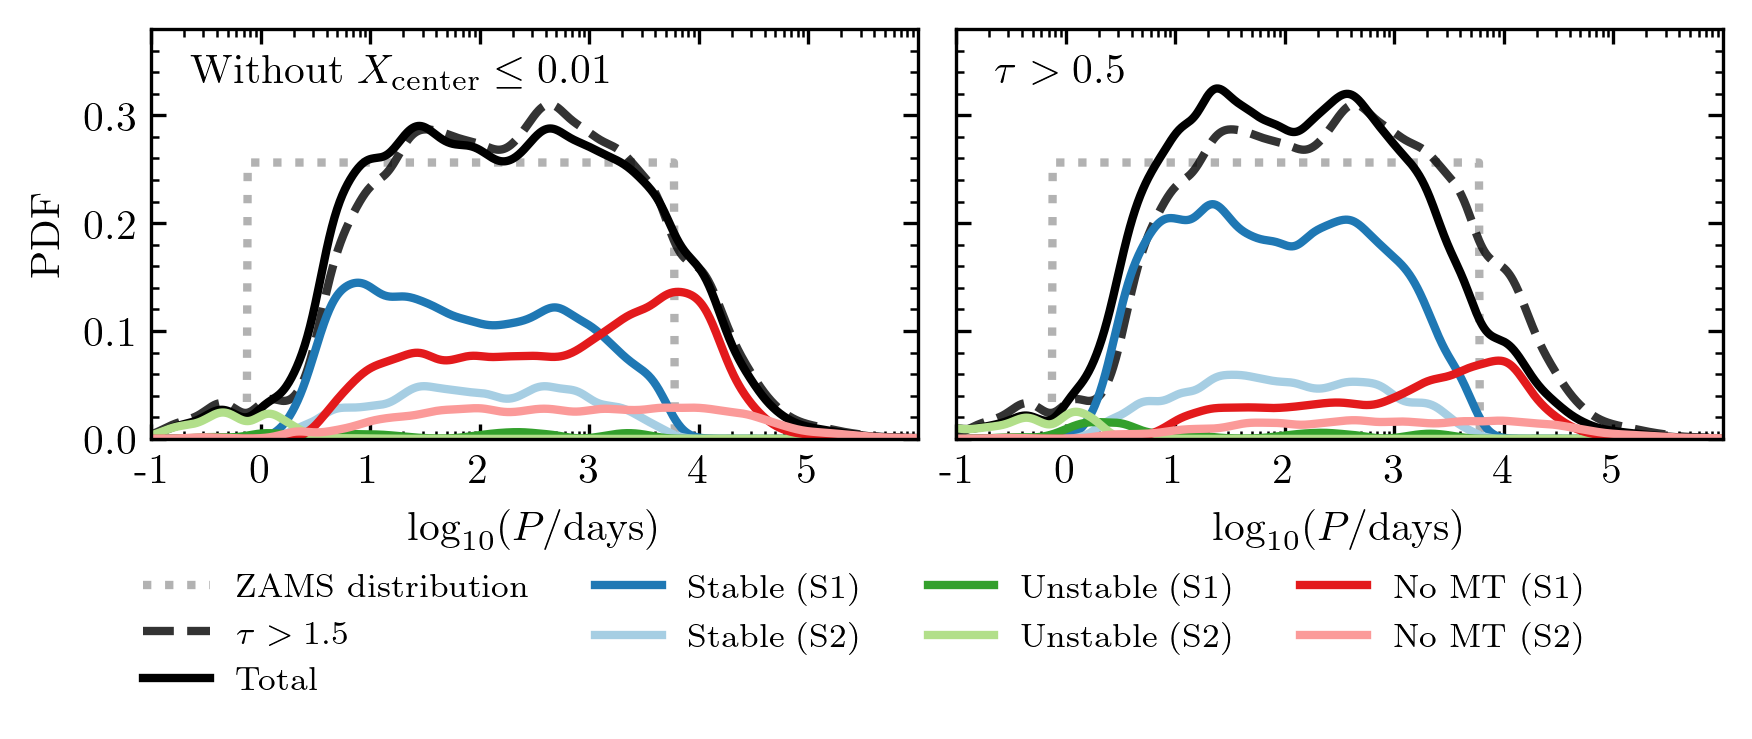

In [ ]:
from posydon.popsyn.distributions import PowerLawPeriod   
from posydon.popsyn.synthetic_population import Population

fig, axes  = plt.subplots(1, 2, figsize=(3.38*2, 2.535*0.7))

PDF_logP = PowerLawPeriod(p_min=0.75, p_max=50000.0, slope=0.0)
x_eval = np.linspace(-1, 7, 1000)


mask = make_binary_mask(WR_data[1.0])


flatP = PDF_logP.pdf(10**x_eval)

for ax in axes:
    ax.plot(10**x_eval, flatP, ls=':',  color='black', linewidth=2, alpha=0.3, 
         label=f'ZAMS distribution')

weights = WR_data[1.0]['weight'] * WR_data[1.0]['model_weight']
period_array = WR_data[1.0]['period']

# plot original total distribution for comparison
WNL, WNE, WC = classify_WR_normal(WR_data[1.0])
WR_mask = WNL | WNE | WC

kde = gaussian_kde(np.log10(period_array[mask & WR_mask]), weights=weights[mask & WR_mask], bw_method=0.1)
kde_eval = kde(x_eval)
axes[0].plot(10**x_eval, kde_eval, color='black', label=r'$\tau>1.5$', linewidth=2, alpha=0.8, ls='--')
axes[1].plot(10**x_eval, kde_eval, color='black', label=r'$\tau>1.5$', linewidth=2, alpha=0.8, ls='--')


count = 0
for label, mask_func in zip(['MS', 'Optical Depth'], [classify_WR_MS, classify_WR_optical_depth]):
    WNL, WNE, WC = mask_func(WR_data[1.0])
    WR_mask = WNL | WNE | WC
    print(weights[mask & WR_mask].sum())
    print(weights[mask & WNL].sum(), weights[mask & WNE].sum(), weights[mask & WC].sum())
    
    # plot total
    kde = gaussian_kde(np.log10(period_array[mask & WR_mask]), weights=weights[mask & WR_mask], bw_method=0.1)
    kde_eval = kde(x_eval)
    axes[count].plot(10**x_eval, kde_eval, color='black', label='Total', linewidth=2)
    
    metallicity = 1.0
    met_str = convert_metallicity_to_string(metallicity)

    population_run_folder = Path('/Users/max/Documents/projects/WR_population/population_synthesis/runs/2026_08_14/')
    population_file = population_run_folder / f"{met_str}_Zsun_population.h5"

    pop = Population(str(population_file))

    HMS_HMS_interaction = pop.oneline['interp_class_HMS_HMS']
    CO_HMS_RLO_interaction = pop.oneline['interp_class_CO_HMS_RLO']

    S1_stable_indices = set(np.where(HMS_HMS_interaction == 'stable_MT')[0])
    S1_unstable_indices = set(np.where(HMS_HMS_interaction == 'unstable_MT')[0])
    S1_reverse_stable_indices = set(np.where(HMS_HMS_interaction == 'reverse_stable_MT')[0])
    S1_no_MT_indices = set(np.where((HMS_HMS_interaction == 'no_MT') | pd.isna(HMS_HMS_interaction))[0])

    # S1 interaction masks - only apply to S1 entries
    S1_entries = (WR_data[metallicity]['star'] == 'S1')
    S1_mask_stable = S1_entries & np.isin(WR_data[metallicity]['key'], np.array(list(S1_stable_indices)))
    S1_mask_unstable = S1_entries & np.isin(WR_data[metallicity]['key'], np.array(list(S1_unstable_indices)))
    S1_mask_reverse_stable = S1_entries & np.isin(WR_data[metallicity]['key'], np.array(list(S1_reverse_stable_indices)))
    S1_mask_no_MT = S1_entries & np.isin(WR_data[metallicity]['key'], np.array(list(S1_no_MT_indices)))


    S2_stable_indices = set(np.where(CO_HMS_RLO_interaction == 'stable_MT')[0])
    S2_unstable_indices = set(np.where(CO_HMS_RLO_interaction == 'unstable_MT')[0])
    S2_reverse_stable_indices = set(np.where(CO_HMS_RLO_interaction == 'reverse_stable_MT')[0])
    S2_no_MT_indices = set(np.where((CO_HMS_RLO_interaction == 'no_MT') | pd.isna(CO_HMS_RLO_interaction))[0])

    # S2 interaction masks - only apply to S2 entries
    S2_entries = (WR_data[metallicity]['star'] == 'S2')
    S2_mask_stable = S2_entries & np.isin(WR_data[metallicity]['key'], np.array(list(S2_stable_indices)))
    S2_mask_unstable = S2_entries & np.isin(WR_data[metallicity]['key'], np.array(list(S2_unstable_indices)))
    S2_mask_reverse_stable = S2_entries & np.isin(WR_data[metallicity]['key'], np.array(list(S2_reverse_stable_indices)))
    S2_mask_no_MT = S2_entries & np.isin(WR_data[metallicity]['key'], np.array(list(S2_no_MT_indices)))
    MT_interactions = {'Stable (S1)': S1_mask_stable,
                   'Stable (S2)': S2_mask_stable,
                   'Unstable (S1)': S1_mask_unstable,
                   'Unstable (S2)': S2_mask_unstable,
                   'No MT (S1)': S1_mask_no_MT,
                   'No MT (S2)': S2_mask_no_MT,
                   'Reverse Stable (S1)': S1_mask_reverse_stable,}
    
    # get covariance
    cho_cov = kde.cho_cov

    # different MT interactions
    print("WNL:", weights[mask & (WNL | WNE | WC)].sum()/weights[mask & (WNL | WNE | WC)].sum())
    total = 0
    not_used_mask = np.ones_like(mask, dtype=bool)  # Track which data points have been used in KDEs
    for label, mt_mask in MT_interactions.items():
        if np.sum(weights[mask & WNL & mt_mask]) == 0:
            continue  # Skip if no data points for this interaction type
        
        # plot histogram 
        kde = gaussian_kde(np.log10(period_array[mask & (WNL | WNE | WC) & mt_mask]), weights=weights[mask & (WNL | WNE | WC) & mt_mask], bw_method=0.1)
        kde.cho_cov = cho_cov # use same covariance for all KDEs to ensure fair comparison
        kde_eval = kde(x_eval)
        fraction = np.sum(weights[mask & (WNL | WNE | WC) & mt_mask]) / np.sum(weights[mask & (WNL | WNE | WC)])
        total += fraction
        print(f"{label}: {fraction*100:.3f}%")
        axes[count].plot(10**x_eval, kde_eval*fraction, label=label, linewidth=2, color=colours[label])
    count += 1

    
    
for ax in axes:
    # Housekeeping for layout
    ax.set_xlabel('$\log_{10}(P/\mathrm{days})$')
    ax.set_xscale('log')
    ax.set_xlim(1e-1, 1e6)
    ax.set_xticks([0.1, 1, 10, 100, 1000, 10000, 100000])
    ax.set_xticklabels(['-1', '0', '1', '2', '3', '4', '5'])
    ax.set_ylim(0, 0.38)


axes[0].set_ylabel('PDF')
#axes[1].set_ylabel('PDF')
axes[1].set_yticklabels([])

axes[1].set_xlabel('$\log_{10}(P/\mathrm{days})$')
axes[0].text(0.05, 0.87, r'Without $X_\mathrm{center} \leq 0.01$ ', transform=axes[0].transAxes)
axes[1].text(0.05, 0.87, r'$\tau>0.5$', transform=axes[1].transAxes)

axes[0].legend(loc='upper left', bbox_to_anchor=(-0.05, -0.25), ncol=4)

plt.subplots_adjust(wspace=0.05, hspace=0.1)


figure_paths = '/Users/max/Documents/projects/WR_population/figure_scripts/figures/'
plt.savefig(figure_paths + 'pdf/MW_other_selection_criteria.pdf', bbox_inches='tight')
plt.savefig(figure_paths + 'png/MW_other_selection_criteria.png', bbox_inches='tight', dpi=300)
plt.show()